# Контроль качества магнитной плитки: классификация дефектов поверхности и проверка на утечку данных

**Автор:** Святослав Тихомиров

**Стек:** Python, OpenCV, NumPy, pandas, SciPy, scikit-image, scikit-learn, PyTorch, torchvision, Albumentations, Matplotlib, Seaborn

## Аннотация

В работе решается задача автоматического визуального контроля: по фотографии поверхности ферритовой магнитной плитки нужно определить, есть ли на ней дефект, и если есть, то какого типа. Последовательно рассмотрены подходы возрастающей сложности:

1. **сегментация по правилам** средствами OpenCV (вычитание фона, порог Оцу, морфология) без обучения;
2. **классическое машинное обучение**: признаки HOG и LBP и метод опорных векторов;
3. **перенос обучения**: признаки предобученной свёрточной сети ResNet-18 и линейный классификатор;
4. **дообучение** той же сети на PyTorch.

Главный результат работы методический. При обычном случайном разбиении классическая модель показывает macro-F1 около 0.95. Проверка обнаружила, что каждый участок плитки снят в наборе примерно шесть раз при разной экспозиции, и почти одинаковые кадры попадают одновременно в обучение и в тест. После разбиения по участкам та же модель даёт macro-F1 около 0.25. Дальнейшее сравнение моделей проведено уже по честной схеме, и в ней заметное преимущество получает перенос обучения.

## Содержание

1. Постановка задачи и данные
2. Разведочный анализ
3. Предобработка изображений
4. Сегментация дефектов без обучения
5. Классический подход и наивная оценка качества
6. Проверка на утечку данных
7. Честная схема оценки
8. Перенос обучения: признаки ResNet-18
9. Дообучение сети на PyTorch
10. Итоговое сравнение
11. Интерпретация: Grad-CAM
12. Выводы

## 1. Постановка задачи и данные

**Данные.** Используется открытый набор *Magnetic Tile Defect* (Huang, Qiu, Yuan, 2020, статья «Surface defect saliency of magnetic tile»). Он содержит 1344 полутоновых снимка участков плитки. Каждый снимок отнесён к одному из шести классов: пять типов дефектов и класс бездефектной поверхности. Для каждого снимка есть попиксельная маска дефекта.

| Класс | Описание |
|---|---|
| `Blowhole` | раковина: маленькое тёмное углубление |
| `Crack` | трещина: тонкая тёмная линия |
| `Break` | скол на краю плитки |
| `Fray` | потёртость, износ поверхности |
| `Uneven` | неравномерная шлифовка, протяжённая область |
| `Free` | дефекта нет |

**Формальная постановка.** Пусть $x \in \mathbb{R}^{H \times W}$ - изображение, $y \in \{1,\dots,6\}$ - метка класса. Требуется построить отображение $f: x \mapsto \hat{y}$, которое хорошо обобщается на новые снимки. Маски дефектов в обучении классификаторов не участвуют. Они используются только для оценки сегментации (раздел 4) и для проверки того, на что смотрит нейросеть (раздел 9).

**Почему выбраны эти инструменты.**

- **OpenCV** - основной инструмент работы с изображением: чтение, изменение размера, фильтрация, выравнивание контраста, пороговая обработка, морфология, поиск контуров. Библиотека написана на C++, поэтому операции выполняются быстро даже на процессоре.
- **scikit-image** - отсюда взяты готовые реализации дескрипторов HOG и LBP, они удобнее в настройке, чем аналоги в OpenCV.
- **scikit-learn** - разбиение выборки, конвейер обработки признаков, подбор гиперпараметров по кросс-валидации, метрики.
- **scikit-learn** здесь же отвечает за разбиение с учётом групп, о котором пойдёт речь в разделах 6 и 7.
- **PyTorch и torchvision** - предобученная свёрточная сеть, извлечение признаков и дообучение.
- **Albumentations** - аугментации изображений. Библиотека работает поверх OpenCV и принимает массивы NumPy, поэтому хорошо стыкуется с остальным кодом.
- **pandas, Matplotlib, Seaborn** - табличное представление метаданных и графики.

In [1]:
import os
import random
import subprocess
import time
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog, local_binary_pattern

from scipy.sparse.csgraph import connected_components

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
import albumentations as A

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=0.95)

print("OpenCV:", cv2.__version__, "| PyTorch:", torch.__version__, "| Albumentations:", A.__version__)

OpenCV: 5.0.0 | PyTorch: 2.15.0+cu132 | Albumentations: 2.0.8


Все случайные элементы (разбиение, инициализация весов, аугментации) зависят от одного зерна генератора. Это нужно для воспроизводимости: повторный запуск ноутбука должен давать те же числа, иначе выводы нельзя проверить.

In [2]:
SEED = 42
IMG_SIZE = 160          # сторона квадрата для классических признаков
NET_SIZE = 224          # сторона квадрата для нейросети (на таком размере она предобучена)
DATA_DIR = Path("data")
FIG_DIR = Path("images")
FIG_DIR.mkdir(exist_ok=True)

CLASSES = ["Blowhole", "Break", "Crack", "Fray", "Uneven", "Free"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Устройство:", DEVICE)

Устройство: cpu


In [3]:
# Датасет не хранится в репозитории проекта: он принадлежит авторам статьи.
# При первом запуске он скачивается из их официального репозитория.
if not DATA_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "--quiet",
                    "https://github.com/abin24/Magnetic-tile-defect-datasets..git", str(DATA_DIR)],
                   check=True)

rows = []
for cls in CLASSES:
    for img_path in sorted((DATA_DIR / f"MT_{cls}" / "Imgs").glob("*.jpg")):
        rows.append({"path": str(img_path),
                     "exposure": int(img_path.name[3]),      # имена файлов имеют вид exp3_num_12345.jpg
                     "mask_path": str(img_path.with_suffix(".png")),
                     "label": cls})
df = pd.DataFrame(rows)
df["y"] = df["label"].map(CLASS_TO_IDX)
print("Всего снимков:", len(df))
df.head(3)

Всего снимков: 1344


,path,exposure,mask_path,label,y
0,data/MT_Blowhole/Imgs/exp1_num_108719.jpg,1,data/MT_Blowhole/Imgs/exp1_num_108719.png,Blowhole,0
1,data/MT_Blowhole/Imgs/exp1_num_108889.jpg,1,data/MT_Blowhole/Imgs/exp1_num_108889.png,Blowhole,0
2,data/MT_Blowhole/Imgs/exp1_num_262480.jpg,1,data/MT_Blowhole/Imgs/exp1_num_262480.png,Blowhole,0


## 2. Разведочный анализ

Перед построением моделей нужно понять три вещи: насколько сбалансированы классы, одинаковы ли снимки по размеру и какую часть кадра занимает дефект. От ответов зависят выбор метрики, способ приведения к единому размеру и ожидаемая сложность каждого класса.

In [4]:
# Для каждого снимка считаем размер и долю пикселей, помеченных в маске как дефект.
heights, widths, fracs = [], [], []
for p, mp in zip(df["path"], df["mask_path"]):
    mask = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    heights.append(mask.shape[0]); widths.append(mask.shape[1])
    fracs.append((mask > 0).mean())
df["height"], df["width"], df["defect_frac"] = heights, widths, fracs

summary = df.groupby("label").agg(
    count=("y", "size"),
    share=("y", lambda s: len(s) / len(df)),
    median_defect_area=("defect_frac", "median"),
).loc[CLASSES]
summary["share"] = (summary["share"] * 100).round(1)
summary["median_defect_area"] = (summary["median_defect_area"] * 100).round(2)
summary.columns = ["Снимков", "Доля, %", "Медианная площадь дефекта, % кадра"]
summary

,Снимков,"Доля, %","Медианная площадь дефекта, % кадра"
label,,,
Blowhole,115,8.6,0.15
Break,85,6.3,1.38
Crack,57,4.2,0.45
Fray,32,2.4,15.82
Uneven,103,7.7,24.70
Free,952,70.8,0.00


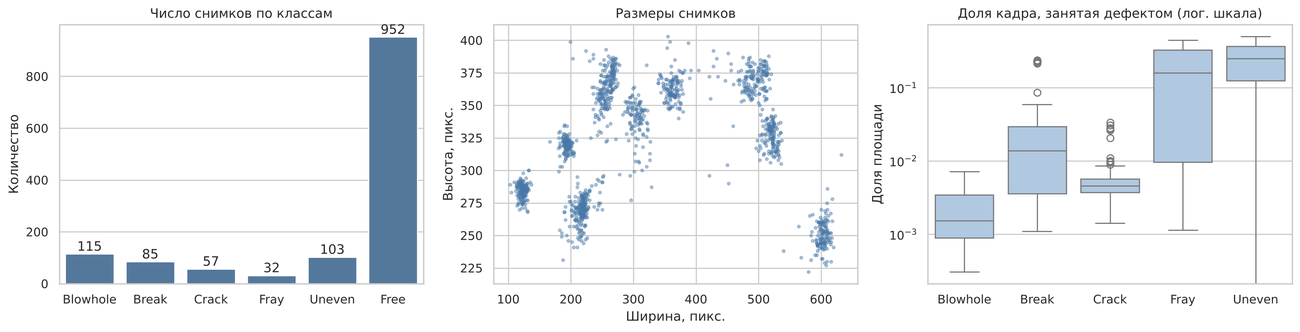

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.countplot(data=df, x="label", order=CLASSES, color="#4878a8", ax=axes[0])
axes[0].set(title="Число снимков по классам", xlabel="", ylabel="Количество")
for c in axes[0].containers:
    axes[0].bar_label(c)

axes[1].scatter(df["width"], df["height"], s=6, alpha=0.4, color="#4878a8")
axes[1].set(title="Размеры снимков", xlabel="Ширина, пикс.", ylabel="Высота, пикс.")

sns.boxplot(data=df[df["label"] != "Free"], x="label", y="defect_frac",
            order=CLASSES[:-1], color="#a8c8e8", ax=axes[2])
axes[2].set_yscale("log")
axes[2].set(title="Доля кадра, занятая дефектом (лог. шкала)", xlabel="", ylabel="Доля площади")
plt.tight_layout(); plt.show()

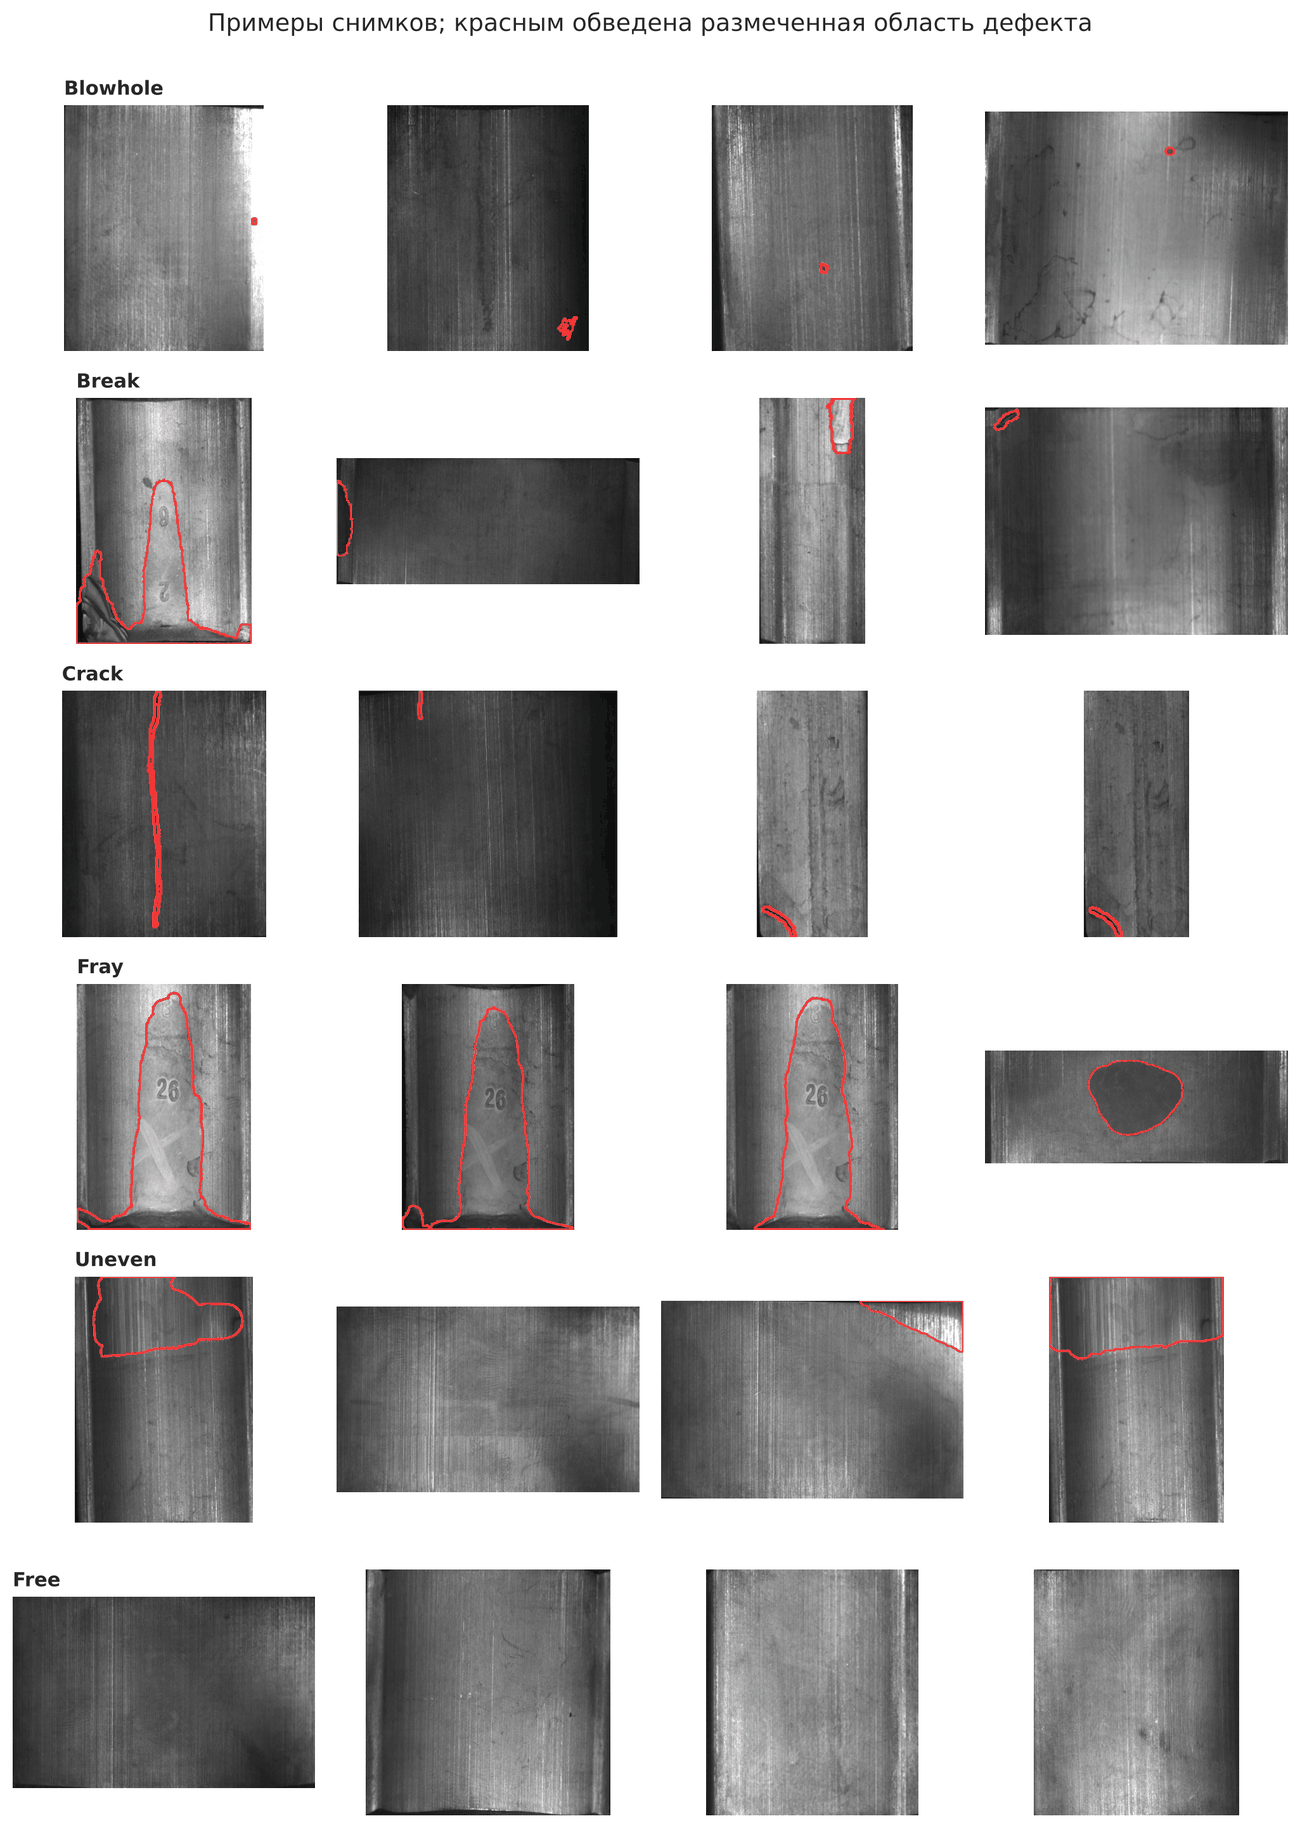

In [6]:
def show_examples(n_per_class=4):
    # Контур дефекта берём из маски: cv2.findContours возвращает границы связных областей.
    fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(2.6 * n_per_class, 2.4 * len(CLASSES)))
    for r, cls in enumerate(CLASSES):
        sample = df[df["label"] == cls].sample(n_per_class, random_state=SEED)
        for c, (_, row) in enumerate(sample.iterrows()):
            img = cv2.imread(row["path"], cv2.IMREAD_GRAYSCALE)
            mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
            vis = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
            contours, _ = cv2.findContours((mask > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(vis, contours, -1, (255, 60, 60), 2)
            axes[r, c].imshow(vis); axes[r, c].axis("off")
            if c == 0:
                axes[r, c].set_title(cls, loc="left", fontsize=11, fontweight="bold")
    plt.suptitle("Примеры снимков; красным обведена размеченная область дефекта", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "examples.png", dpi=110, bbox_inches="tight"); plt.show()

show_examples()

**Наблюдения.**

1. **Классы сильно несбалансированы.** Бездефектных снимков около 71 %, а самого редкого класса `Fray` всего 32 штуки. Модель, которая всегда отвечает «дефекта нет», получит точность 71 %, не решив задачу. Значит, доля правильных ответов (accuracy) как основная метрика не годится.
2. **Снимки разного размера и с разным соотношением сторон.** Перед подачей в модель их придётся привести к общему размеру.
3. **Дефекты различаются по площади на два порядка.** Раковины и трещины занимают доли процента кадра, а потёртости и неравномерная шлифовка - десятки процентов. Мелкие дефекты легко потерять при сильном уменьшении снимка, поэтому снимки приводятся к размеру не меньше 160 пикселей по стороне.
4. **Фон неоднороден.** На снимках видны блики, градиент освещённости и текстура шлифовки. Это заранее подсказывает, что простое пороговое правило по яркости будет давать ложные срабатывания.

## 3. Предобработка изображений

Предобработка состоит из двух шагов.

**Приведение к квадрату фиксированного размера.** При уменьшении используется интерполяция `cv2.INTER_AREA`: значение нового пикселя получается усреднением по площади исходных. В отличие от билинейной интерполяции это подавляет муар и ступенчатость при уменьшении, поэтому такой способ рекомендован в документации OpenCV именно для сжатия. Соотношение сторон при этом искажается. Это осознанное упрощение: для классификации типа дефекта форма кадра вторична, а добавление полей (паддинг) создало бы на снимке искусственные границы.

**Выравнивание контраста методом CLAHE.** Обычное выравнивание гистограммы строит функцию преобразования яркости по всему кадру:

$$T(k) = (L-1)\sum_{j=0}^{k} p_j,$$

где $p_j$ - доля пикселей с яркостью $j$, $L = 256$. При неравномерном освещении это плохо работает: яркий блик «съедает» весь динамический диапазон. CLAHE (Contrast Limited Adaptive Histogram Equalization) строит такое преобразование отдельно для каждой плитки сетки $8 \times 8$ и билинейно сшивает результаты. Кроме того, гистограмма каждой плитки обрезается на уровне `clipLimit`, а срезанная часть равномерно перераспределяется. Обрезка ограничивает наклон $T(k)$ и не даёт усиливать шум на однородных участках.

Для нашей задачи это полезно по двум причинам: локальный контраст мелких дефектов возрастает, а различия в общей освещённости между снимками сглаживаются.

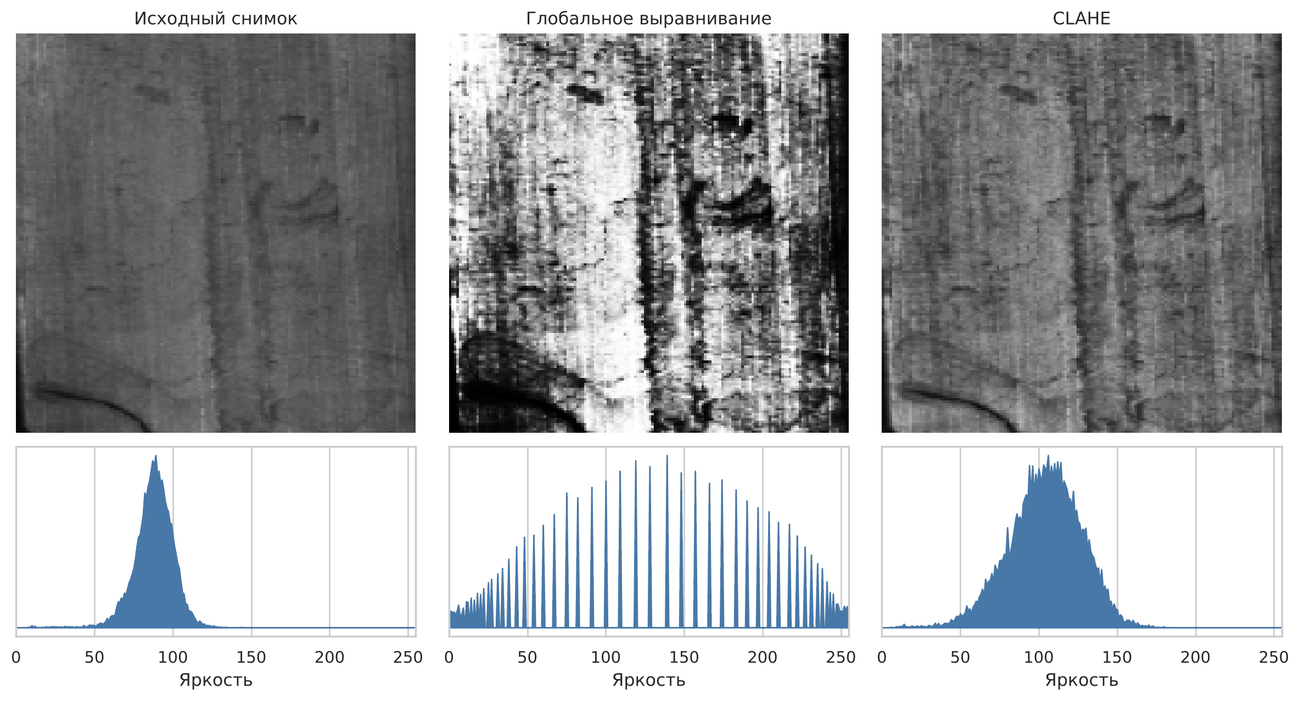

In [7]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess(path, size=IMG_SIZE, use_clahe=True):
    # Чтение в оттенках серого, уменьшение усреднением по площади, выравнивание контраста.
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    if use_clahe:
        img = CLAHE.apply(img)
    return img

example = df[df["label"] == "Crack"].sample(1, random_state=3).iloc[0]
raw = preprocess(example["path"], use_clahe=False)
eq = cv2.equalizeHist(raw)
cl = preprocess(example["path"])

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), gridspec_kw={"height_ratios": [3, 1.3]})
for i, (im, title) in enumerate([(raw, "Исходный снимок"), (eq, "Глобальное выравнивание"), (cl, "CLAHE")]):
    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, i].set_title(title); axes[0, i].axis("off")
    # cv2.calcHist считает гистограмму яркости по 256 уровням
    h = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
    axes[1, i].fill_between(range(256), h, color="#4878a8"); axes[1, i].set_xlim(0, 255)
    axes[1, i].set_xlabel("Яркость"); axes[1, i].set_yticks([])
plt.tight_layout(); plt.show()

Глобальное выравнивание растягивает гистограмму на весь диапазон, но вместе с дефектом усиливает и зернистость фона. CLAHE действует мягче: дефект становится контрастнее, а фон остаётся относительно спокойным. Дальше во всех экспериментах используется CLAHE.

Все снимки небольшие, поэтому их удобно один раз обработать и держать в памяти в двух размерах: 160 пикселей для классических признаков и 224 пикселя для нейросети.

In [8]:
X_img = np.stack([preprocess(p) for p in df["path"]])                    # (N, 160, 160), uint8
X_net = np.stack([preprocess(p, size=NET_SIZE) for p in df["path"]])     # (N, 224, 224), uint8
y_all = df["y"].to_numpy()
N = len(y_all)
print(X_img.shape, X_net.shape, X_img.dtype)

(1344, 160, 160) (1344, 224, 224) uint8


## 4. Сегментация дефектов без обучения

Прежде чем обучать модели, стоит проверить, нельзя ли найти дефект набором простых правил. Если можно, машинное обучение здесь было бы излишним.

**Идея.** Раковины и трещины выглядят как тёмные пятна на более светлом фоне. Алгоритм:

1. **Сглаживание** фильтром Гаусса $5 \times 5$ для подавления зернистости.
2. **Оценка фона** медианным фильтром с большим окном ($31 \times 31$). Медиана устойчива к выбросам, поэтому мелкие тёмные объекты из оценки фона исчезают, а плавные изменения освещённости сохраняются.
3. **Вычитание**: $D = \max(B - I,\, 0)$, где $B$ - фон, $I$ - снимок. На карте $D$ яркими остаются только участки, которые темнее своего окружения.
4. **Бинаризация по Оцу.** Метод Оцу выбирает порог $t$, максимизирующий межклассовую дисперсию

$$\sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,\bigl(\mu_0(t) - \mu_1(t)\bigr)^2,$$

где $\omega_{0,1}$ - доли пикселей ниже и выше порога, $\mu_{0,1}$ - их средние яркости. У метода есть известная особенность: он всегда делит пиксели на два класса, даже если дефекта на снимке нет. Поэтому дополнительно введена нижняя граница порога.
5. **Морфологическая очистка.** Открытие (эрозия, затем дилатация) удаляет одиночные шумовые точки. Закрытие (дилатация, затем эрозия) соединяет близкие фрагменты одного дефекта.
6. **Отбор связных компонент** по площади: слишком мелкие области отбрасываются.

**Метрика.** Качество маски оценивается мерой Жаккара (IoU, Intersection over Union):

$$\mathrm{IoU}(P, G) = \frac{|P \cap G|}{|P \cup G|},$$

где $P$ - предсказанная маска, $G$ - размеченная. IoU выбрана вместо попиксельной точности потому, что дефект занимает малую долю кадра: маска из одних нулей дала бы точность выше 99 %.

In [9]:
SEG_SIZE = 256   # сегментация выполняется в более высоком разрешении, чтобы не терять мелкие дефекты

def segment_dark_defects(gray, bg_ksize=31, min_thr=25, min_area=20):
    # Возвращает бинарную маску участков, которые заметно темнее локального фона.
    smooth = cv2.GaussianBlur(gray, (5, 5), 0)
    background = cv2.medianBlur(smooth, bg_ksize)
    diff = cv2.subtract(background, smooth)               # отрицательные значения обрезаются до нуля
    otsu_thr, _ = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = (diff > max(otsu_thr, min_thr)).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7)))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    clean = np.zeros_like(mask)
    for i in range(1, n):                                  # компонента 0 - это фон
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean[labels == i] = 255
    return clean

def iou(pred, gt):
    union = np.logical_or(pred, gt).sum()
    return np.logical_and(pred, gt).sum() / union if union > 0 else 1.0

seg_rows = []
for _, row in df.iterrows():
    gray = preprocess(row["path"], size=SEG_SIZE)
    gt = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    # маску уменьшаем методом ближайшего соседа, чтобы она осталась бинарной
    gt = cv2.resize(gt, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_NEAREST) > 0
    pred = segment_dark_defects(gray) > 0
    seg_rows.append({"label": row["label"], "IoU": iou(pred, gt), "found": pred.any()})

seg_df = pd.DataFrame(seg_rows)
seg_table = seg_df.groupby("label").agg(mean_IoU=("IoU", "mean"), found_share=("found", "mean")).loc[CLASSES].round(3)
seg_table.columns = ["Средний IoU", "Доля снимков, где что-то найдено"]
seg_table

,Средний IoU,"Доля снимков, где что-то найдено"
label,,
Blowhole,0.123,1.000
Break,0.058,0.976
Crack,0.137,0.895
Fray,0.053,1.000
Uneven,0.028,1.000
Free,0.032,0.968


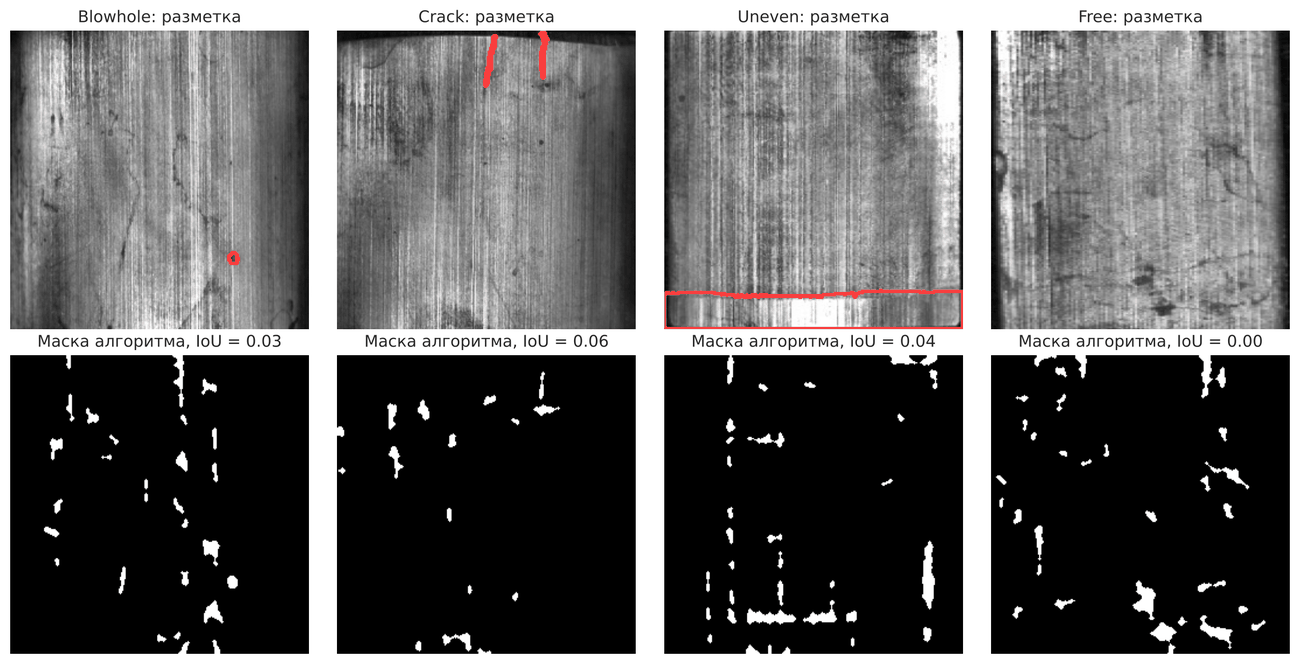

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6.6))
picks = [("Blowhole", 1), ("Crack", 5), ("Uneven", 2), ("Free", 4)]
for c, (cls, rs) in enumerate(picks):
    row = df[df["label"] == cls].sample(1, random_state=rs).iloc[0]
    gray = preprocess(row["path"], size=SEG_SIZE)
    gt = cv2.resize(cv2.imread(row["mask_path"], 0), (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_NEAREST) > 0
    pred = segment_dark_defects(gray)
    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    cnt_gt, _ = cv2.findContours(gt.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis, cnt_gt, -1, (255, 60, 60), 2)
    axes[0, c].imshow(vis); axes[0, c].set_title(f"{cls}: разметка"); axes[0, c].axis("off")
    axes[1, c].imshow(pred, cmap="gray"); axes[1, c].set_title(f"Маска алгоритма, IoU = {iou(pred > 0, gt):.2f}"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

**Вывод по разделу.** Алгоритм по правилам с задачей не справляется.

- Даже на «своих» классах (`Blowhole`, `Crack`) средний IoU мал. Вместе с настоящим дефектом в маску попадают тёмные границы плитки, тени и следы шлифовки.
- На бездефектных снимках алгоритм почти всегда что-то находит. Использовать его как детектор «есть дефект / нет дефекта» нельзя: он не отличает дефект от обычной неоднородности фона.
- Для протяжённых дефектов (`Uneven`, `Fray`) подход неприменим в принципе: они отличаются от фона не яркостью, а текстурой.

Причина в том, что признак «темнее окружения» необходим, но не достаточен. Нужны признаки, описывающие форму и текстуру, и способ автоматически подобрать решающее правило по размеченным примерам. Этим занимаются следующие разделы. Сами операции OpenCV при этом остаются полезными: они используются в предобработке, визуализации контуров и построении тепловых карт.

Стоит оговорить, что проверен один конкретный набор правил с вручную выбранными параметрами. Более тонкая настройка могла бы улучшить результат на мелких тёмных дефектах, но не устранила бы ложные срабатывания на годных плитках.

## 5. Классический подход и наивная оценка качества

Классическое компьютерное зрение разделяет задачу на два этапа: сначала по изображению вычисляется вектор признаков фиксированной длины, затем на этих векторах обучается обычный классификатор. Выбраны два дескриптора, которые дополняют друг друга.

**HOG (Histogram of Oriented Gradients)** описывает форму. В каждом пикселе вычисляется градиент яркости с модулем $m = \sqrt{g_x^2 + g_y^2}$ и направлением $\theta = \operatorname{arctg}(g_y / g_x)$. Изображение делится на ячейки, и в каждой строится гистограмма направлений, взвешенная модулями. Гистограммы соседних ячеек объединяются в блоки и нормируются, что делает дескриптор устойчивым к изменению освещённости. HOG хорошо улавливает вытянутые структуры с выраженным направлением: трещины, границы сколов.

**LBP (Local Binary Patterns)** описывает текстуру. Яркость каждого пикселя сравнивается с яркостью $P$ соседей на окружности радиуса $R$:

$$\mathrm{LBP}_{P,R} = \sum_{p=0}^{P-1} s(g_p - g_c)\, 2^p, \qquad s(z) = \begin{cases}1, & z \ge 0\\ 0, & z < 0\end{cases}$$

Получается код локального узора, а признаком служит гистограмма этих кодов по всему снимку. Используется вариант `uniform`, в котором сохраняются только узоры с не более чем двумя переходами 0/1 (края, углы, пятна). Это сокращает гистограмму до $P + 2$ столбцов и делает её инвариантной к повороту. LBP нужен для классов `Fray` и `Uneven`, которые отличаются именно фактурой поверхности.

**Классификатор.** Используется метод опорных векторов с радиальным ядром $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$. На небольших выборках с большим числом признаков SVM обычно работает надёжно: решение определяется только опорными объектами, а параметр $C$ управляет компромиссом между шириной зазора и ошибками на обучении. Конвейер состоит из трёх шагов:

1. `StandardScaler` приводит признаки к нулевому среднему и единичной дисперсии. Для RBF-ядра это обязательно, так как оно зависит от евклидова расстояния.
2. `PCA` оставляет главные компоненты, объясняющие 95 % дисперсии. Признаков HOG несколько тысяч при тысяче объектов, и снижение размерности уменьшает риск переобучения.
3. `SVC` с `class_weight="balanced"`: штраф за ошибку на объекте обратно пропорционален частоте его класса, что компенсирует дисбаланс.

Все шаги объединены в `Pipeline`. Тогда при кросс-валидации параметры масштабирования и PCA оцениваются только по обучающей части каждого фолда и не «видят» проверочную.

**Метрики.** Для класса $c$ точность (precision), полнота (recall) и F1-мера равны

$$P_c = \frac{TP_c}{TP_c + FP_c}, \qquad R_c = \frac{TP_c}{TP_c + FN_c}, \qquad F1_c = \frac{2 P_c R_c}{P_c + R_c}.$$

- **Macro-F1** $= \frac{1}{K}\sum_c F1_c$ - основная метрика. Усреднение по классам без весов означает, что редкий класс влияет на итог так же, как частый. Для контроля качества это правильно: пропущенная трещина не менее важна, чем верно распознанная годная плитка.
- **Balanced accuracy** $= \frac{1}{K}\sum_c R_c$ - средняя полнота по классам.
- **ROC-AUC в бинарной постановке «дефект / годная»** - вероятность того, что случайно взятый дефектный снимок получит от модели более высокую оценку «дефектности», чем случайно взятый годный. Эта метрика не зависит от выбора порога и отвечает на практический вопрос: можно ли использовать модель для отбраковки.
- **Accuracy** приводится справочно, чтобы показать, насколько она обманчива при дисбалансе.

In [11]:
def extract_features(img):
    # HOG: ячейки 16x16, блоки 2x2 ячейки, 9 направлений - стандартные параметры из работы Dalal & Triggs
    f_hog = hog(img, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                block_norm="L2-Hys", feature_vector=True)
    # LBP на двух масштабах: мелкая и более крупная текстура
    f_lbp = []
    for P, R in [(8, 1), (16, 2)]:
        codes = local_binary_pattern(img, P, R, method="uniform")
        hist, _ = np.histogram(codes, bins=P + 2, range=(0, P + 2), density=True)
        f_lbp.append(hist)
    return np.concatenate([f_hog, *f_lbp])

t0 = time.time()
X_feat = np.stack([extract_features(im) for im in X_img])
print(f"Матрица признаков: {X_feat.shape}, время извлечения: {time.time() - t0:.1f} с")

Матрица признаков: (1344, 2944), время извлечения: 15.1 с


Начнём с самой распространённой схемы оценки: стратифицированная 5-кратная кросс-валидация со случайным разбиением снимков. Гиперпараметры SVM подбираются по сетке.

In [12]:
svm_pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=SEED)),
                     ("svm", SVC(kernel="rbf", class_weight="balanced"))])

param_grid = {"svm__C": [1, 10, 100], "svm__gamma": ["scale", 1e-3, 1e-4]}
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(svm_pipe, param_grid, scoring="f1_macro", cv=random_cv, n_jobs=-1)
grid.fit(X_feat, y_all)

cv_table = pd.DataFrame(grid.cv_results_)[["param_svm__C", "param_svm__gamma", "mean_test_score", "std_test_score"]]
cv_table.columns = ["C", "gamma", "Macro-F1 (среднее по фолдам)", "Ст. отклонение"]
print("Лучшие параметры:", grid.best_params_)
cv_table.sort_values("Macro-F1 (среднее по фолдам)", ascending=False).round(3).head(4)

Лучшие параметры: {'svm__C': 100, 'svm__gamma': 0.0001}


,C,gamma,Macro-F1 (среднее по фолдам),Ст. отклонение
8,100,0.0001,0.954,0.022
0,1,scale,0.953,0.022
3,10,scale,0.953,0.027
6,100,scale,0.953,0.027


Результат выглядит отличным: macro-F1 0.954 на шести классах, причём у самого редкого класса всего 32 снимка. Именно это и настораживает. Раздел 4 показал, что дефекты трудноотличимы от фона, а простые признаки на маленькой выборке редко дают такое качество. Когда результат слишком хорош, первым делом стоит проверить схему оценки.

## 6. Проверка на утечку данных

**Утечка данных** - ситуация, когда в обучающую выборку попадает информация, которой у модели не будет при реальном применении. Частный случай - почти одинаковые объекты в обучении и в тесте. Тогда тест проверяет не умение обобщать, а умение запоминать.

Повод для подозрений есть в самих именах файлов: `exp1_num_…`, `exp2_num_…`, …, `exp6_num_…`. В каждом классе снимки делятся между шестью значениями `exp` почти поровну (ещё три файла помечены как `exp0`). Это похоже на шесть серий съёмки одних и тех же участков.

Проверим гипотезу напрямую. Для каждого снимка найдём самые похожие на него среди остальных. Мерой сходства служит косинус угла между HOG-дескрипторами уменьшенных копий ($64 \times 64$). Блочная нормировка HOG делает дескриптор мало чувствительным к яркости, поэтому один и тот же участок при разной экспозиции должен давать близкие векторы.

In [13]:
pd.crosstab(df["label"], df["exposure"]).loc[CLASSES]

exposure,0,1,2,3,4,5,6
label,,,,,,,
Blowhole,0,20,19,20,18,19,19
Break,0,12,14,16,14,14,15
Crack,0,9,9,9,10,10,10
Fray,1,6,5,4,5,5,6
Uneven,1,17,17,17,17,17,17
Free,1,157,159,157,160,160,158


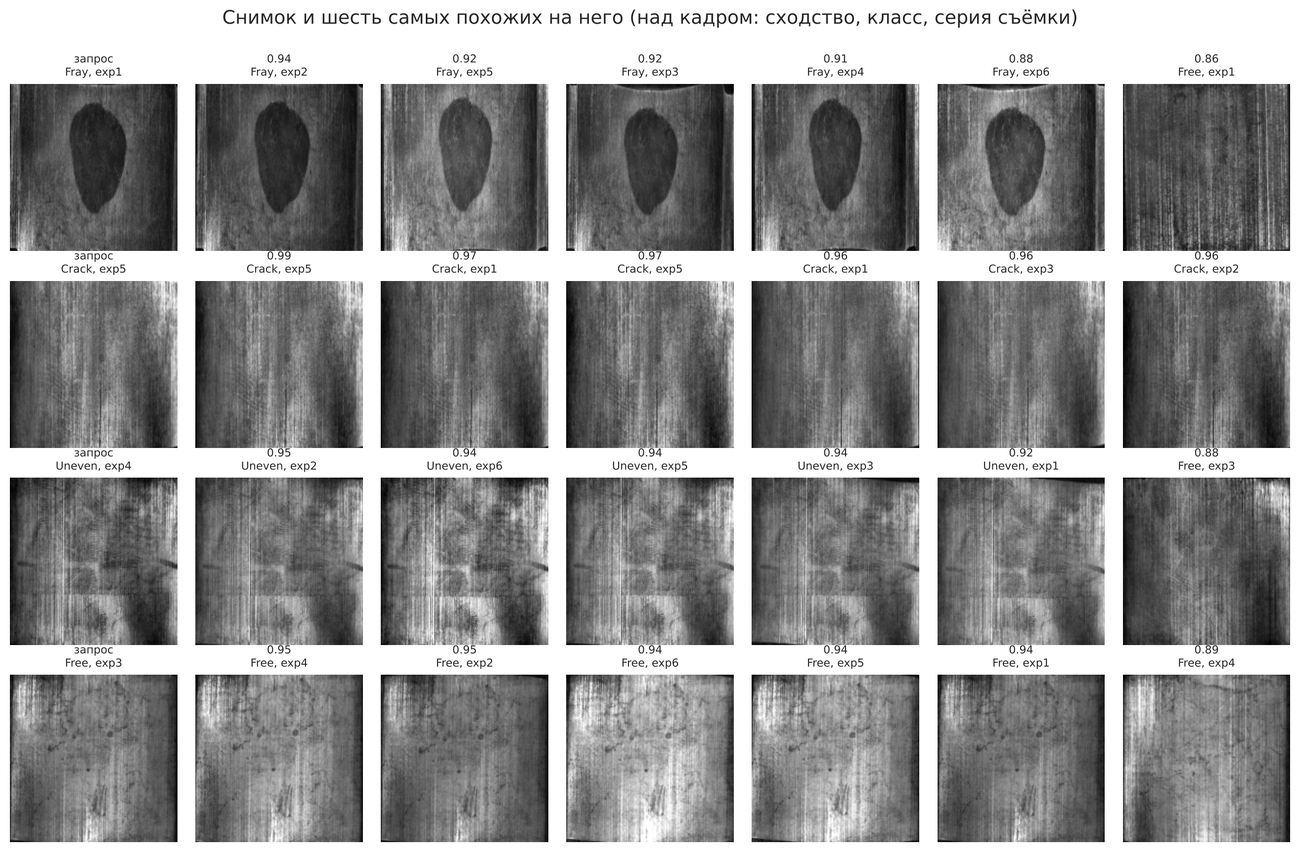

In [14]:
def thumb_descriptor(img):
    small = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA)
    f = hog(small, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True)
    return f / np.linalg.norm(f)

D = np.stack([thumb_descriptor(im) for im in X_img])
S = D @ D.T                      # матрица косинусного сходства: векторы нормированы, достаточно скалярного произведения
np.fill_diagonal(S, -1)          # сам с собой снимок не сравниваем

def show_neighbours(indices, k=6):
    fig, axes = plt.subplots(len(indices), k + 1, figsize=(1.9 * (k + 1), 2.15 * len(indices)))
    for r, i in enumerate(indices):
        order = np.argsort(-S[i])[:k]
        for c, j in enumerate([i, *order]):
            axes[r, c].imshow(X_img[j], cmap="gray"); axes[r, c].axis("off")
            title = "запрос" if c == 0 else f"{S[i, j]:.2f}"
            axes[r, c].set_title(f"{title}\n{df.loc[j, 'label']}, exp{df.loc[j, 'exposure']}", fontsize=8)
    plt.suptitle("Снимок и шесть самых похожих на него (над кадром: сходство, класс, серия съёмки)", y=1.0)
    plt.tight_layout(); plt.savefig(FIG_DIR / "duplicates.png", dpi=110, bbox_inches="tight"); plt.show()

rng = np.random.default_rng(SEED)
show_neighbours([int(rng.choice(np.where(y_all == CLASS_TO_IDX[c])[0])) for c in ["Fray", "Crack", "Uneven", "Free"]])

In [15]:
nearest = S.argmax(axis=1)
print(f"Доля снимков, у которых ближайший сосед того же класса: {(y_all[nearest] == y_all).mean():.3f}")
print(f"Доля снимков, у которых ближайший сосед из другой серии съёмки: "
      f"{(df['exposure'].to_numpy()[nearest] != df['exposure'].to_numpy()).mean():.3f}")

Доля снимков, у которых ближайший сосед того же класса: 0.989
Доля снимков, у которых ближайший сосед из другой серии съёмки: 0.986


Гипотеза подтверждается. Ближайшие соседи снимка - это тот же участок той же плитки, как правило снятый в других сериях. Изредка в одной серии встречаются два почти одинаковых кадра, как во второй строке рисунка. Простейшее правило «присвоить класс самого похожего снимка» угадывает класс почти всегда, и никакого распознавания дефектов для этого не нужно.

При случайном разбиении копии одного участка попадают и в обучение, и в тест. SVM с RBF-ядром по сути сравнивает объект с опорными объектами, поэтому охотно этим пользуется. Оценка 0.95 из раздела 5 измеряет способность узнать уже виденную плитку.

**Восстановление групп.** Чтобы оценивать качество честно, все снимки одного участка должны целиком находиться либо в обучении, либо в тесте. Явного идентификатора участка в данных нет, поэтому группы восстанавливаются по сходству:

1. Для каждого снимка берутся пять ближайших соседей среди снимков того же класса из других серий (в группе не должно быть двух кадров одной серии).
2. Между снимками проводится ребро, если каждый из них входит в пятёрку ближайших другого. Требование взаимности отсекает случайные совпадения.
3. Группы - это компоненты связности получившегося графа.

In [16]:
def build_groups(S, labels, exposures, k=5):
    S_valid = S.copy()
    S_valid[labels[:, None] != labels[None, :]] = -1        # соседи только своего класса
    S_valid[exposures[:, None] == exposures[None, :]] = -1  # и только из других серий съёмки
    top = np.argsort(-S_valid, axis=1)[:, :k]
    is_top = np.zeros(S.shape, dtype=bool)
    np.put_along_axis(is_top, top, True, axis=1)
    mutual = is_top & is_top.T                               # ребро есть, только если сходство взаимное
    n_groups, group_id = connected_components(mutual, directed=False)
    return n_groups, group_id

n_groups, groups = build_groups(S, y_all, df["exposure"].to_numpy())
df["group"] = groups

sizes = pd.Series(groups).value_counts()
print(f"Найдено групп: {n_groups}; из них ровно по 6 снимков: {(sizes == 6).sum()}")
unique_table = df.groupby("label").agg(images=("y", "size"), tiles=("group", "nunique")).loc[CLASSES]
unique_table.columns = ["Снимков", "Уникальных участков"]
unique_table.loc["Всего"] = unique_table.sum()
unique_table

Найдено групп: 227; из них ровно по 6 снимков: 195


,Снимков,Уникальных участков
label,,
Blowhole,115,20
Break,85,15
Crack,57,12
Fray,32,4
Uneven,103,17
Free,952,159
Всего,1344,227


Большинство групп состоит ровно из шести снимков, по одному на серию, что согласуется с гипотезой. Оставшиеся группы немного меньше или больше: алгоритм эвристический и иногда объединяет два похожих участка или не находит одну из копий. Для нашей цели это допустимо. Объединение лишних снимков в группу делает разбиение только строже, а неприсоединённые копии единичны.

Таблица меняет представление о данных. Реальный объём выборки - не 1344 снимка, а около 230 участков, из которых дефектных всего 68. На класс `Fray` приходится 4 участка, на `Crack` - 12. Это очень мало, и рассчитывать на высокое качество шестиклассовой классификации уже не приходится.

Теперь повторим оценку той же модели с теми же гиперпараметрами, но разобьём данные с помощью `StratifiedGroupKFold`. Этот метод сохраняет доли классов в фолдах и при этом гарантирует, что снимки одной группы не разделяются.

In [17]:
group_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_feat, y_all, groups))

best_svm = grid.best_estimator_
f1_random = grid.best_score_
pred_svm = cross_val_predict(best_svm, X_feat, y_all, cv=group_folds, n_jobs=-1)
f1_group = f1_score(y_all, pred_svm, average="macro")

leak = pd.DataFrame({"Macro-F1": [f1_random, f1_group]},
                    index=["Случайное разбиение снимков", "Разбиение по участкам плитки"]).round(3)
leak

,Macro-F1
Случайное разбиение снимков,0.954
Разбиение по участкам плитки,0.252


**Вывод по разделу.** Модель и гиперпараметры в двух строках таблицы одинаковы, изменился только способ разбиения. Macro-F1 упал с 0.954 до 0.252. Следовательно, почти вся «точность» наивной оценки объяснялась утечкой: модель узнавала уже виденные участки, а не распознавала дефекты.

Отсюда два практических правила, которые используются дальше.

1. Если один физический объект представлен в данных несколькими снимками, разбивать нужно объекты, а не снимки.
2. Число независимых наблюдений определяется числом объектов. При оценке разброса метрик единицей выборки тоже должен быть участок, а не кадр.

## 7. Честная схема оценки

Все дальнейшие сравнения проводятся по одной схеме.

- **5-кратная кросс-валидация по группам.** Каждый снимок ровно один раз оказывается в проверочном фолде, и в этот момент модель не видела ни одного кадра того же участка. Предсказания по всем пяти фолдам объединяются, и метрики считаются по всей выборке. Отдельная тестовая выборка при 4-20 участках на класс получилась бы слишком маленькой, поэтому используется кросс-валидация.
- **Доверительные интервалы строятся бутстрепом по группам.** Обычный бутстреп предполагает независимость объектов, а снимки одного участка сильно зависимы. Поэтому с возвращением выбираются не снимки, а целые группы (кластерный бутстреп). Границы 95 %-го интервала - это 2.5-й и 97.5-й процентили метрики по 1000 повторам.
- **Точка отсчёта** - константный прогноз самого частого класса.

Гиперпараметры SVM в честной схеме заново не подбираются: используются значения из раздела 5. Они выбраны по «протёкшей» оценке и могут быть не оптимальны, зато итоговая цифра не подогнана под проверочные фолды.

In [18]:
results, predictions, defect_scores = {}, {}, {}
FREE = CLASS_TO_IDX["Free"]

def evaluate(name, y_pred, defect_score=None):
    # defect_score - любая величина, которая тем больше, чем увереннее модель в наличии дефекта.
    row = {"Accuracy": accuracy_score(y_all, y_pred),
           "Balanced accuracy": balanced_accuracy_score(y_all, y_pred),
           "Macro-F1": f1_score(y_all, y_pred, average="macro"),
           "ROC-AUC (дефект / годная)": roc_auc_score(y_all != FREE, defect_score) if defect_score is not None else 0.5}
    results[name], predictions[name], defect_scores[name] = row, np.asarray(y_pred), defect_score
    return pd.Series(row).round(3)

# Константный прогноз: всегда самый частый класс. Его ROC-AUC по определению равен 0.5.
evaluate("Константный прогноз", np.full(N, np.bincount(y_all).argmax()))

Accuracy                     0.708
Balanced accuracy            0.167
Macro-F1                     0.138
ROC-AUC (дефект / годная)    0.500
dtype: float64

In [19]:
# Для ROC-AUC нужна непрерывная оценка. У SVM это значение решающей функции:
# чем оно ниже для класса Free, тем больше модель склоняется к дефекту.
svm_decision = cross_val_predict(best_svm, X_feat, y_all, cv=group_folds, n_jobs=-1, method="decision_function")
evaluate("HOG + LBP + SVM", pred_svm, -svm_decision[:, FREE])

Accuracy                     0.713
Balanced accuracy            0.236
Macro-F1                     0.252
ROC-AUC (дефект / годная)    0.728
dtype: float64

## 8. Перенос обучения: признаки ResNet-18

Обучить свёрточную сеть с нуля на двух сотнях участков нереально: даже у небольшой сети сотни тысяч параметров, и она просто запомнит обучающие кадры. Стандартный выход - **перенос обучения** (transfer learning). Берётся сеть, уже обученная на большом наборе ImageNet (1.28 млн фотографий, 1000 классов). Её первые слои выделяют универсальные элементы изображения: края, углы, пятна, текстуры. Такие элементы полезны и для снимков плитки, хотя плиток в ImageNet нет.

**Архитектура.** ResNet-18 выбрана как самая лёгкая из распространённых сетей: 11 млн параметров, обучение и применение возможны на процессоре. Её ключевая идея - остаточные связи: блок вычисляет не само преобразование $H(x)$, а добавку к входу, $H(x) = x + F(x)$. Благодаря этому градиент свободно проходит через много слоёв, и глубокая сеть обучается устойчиво.

**Самый простой вариант переноса** - не менять веса сети вообще. Сеть используется как готовый экстрактор признаков, а поверх обучается линейный классификатор (логистическая регрессия). Обучаемых параметров при этом на порядки меньше, чем при дообучении всей сети, что важно при таком объёме данных. Кроме того, признаки считаются один раз, и кросс-валидация занимает секунды.

**Какие признаки брать.** Стандартно берут выход последнего блока (`layer4`), усреднённый по пространству. Для дефектов это не лучший выбор по двум причинам:

- раковина занимает доли процента кадра, и при усреднении по всей карте её отклик растворяется. Поэтому к среднему добавляется **максимум** по карте: он реагирует на сильный отклик в одной точке;
- последний блок кодирует крупные, «смысловые» признаки ImageNet. Текстурная информация лучше сохраняется в предыдущем блоке (`layer3`), поэтому используются оба.

Чтобы проверить эти соображения, сравниваются три варианта признаков.

**Технические детали.** Сеть ожидает трёхканальное изображение, поэтому полутоновый кадр копируется в три канала и нормируется средним и отклонением ImageNet, как при предобучении. Веса загружаются из официального релиза библиотеки `timm` на GitHub (архитектура идентична `torchvision.models.resnet18`).

In [20]:
WEIGHTS_URL = ("https://github.com/huggingface/pytorch-image-models/releases/download/"
               "v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth")
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def load_resnet18():
    net = torchvision.models.resnet18()
    state = torch.hub.load_state_dict_from_url(WEIGHTS_URL, map_location="cpu", progress=False)
    net.load_state_dict(state)
    return net

def to_tensor(batch_uint8):
    # (B, H, W) uint8 -> (B, 3, H, W) float32, нормированный как при предобучении
    x = torch.from_numpy(batch_uint8.astype(np.float32) / 255.0).unsqueeze(1).repeat(1, 3, 1, 1)
    return (x - IMAGENET_MEAN) / IMAGENET_STD

@torch.no_grad()
def extract_deep_features(net, images, batch_size=64):
    net.eval()   # режим применения: BatchNorm использует накопленные статистики
    feats = {"l3_avg": [], "l3_max": [], "l4_avg": [], "l4_max": []}
    for b in range(0, len(images), batch_size):
        x = to_tensor(images[b:b + batch_size]).to(DEVICE)
        x = net.maxpool(net.relu(net.bn1(net.conv1(x))))
        l3 = net.layer3(net.layer2(net.layer1(x)))      # (B, 256, 14, 14)
        l4 = net.layer4(l3)                              # (B, 512, 7, 7)
        feats["l3_avg"].append(l3.mean(dim=(2, 3)).cpu()); feats["l3_max"].append(l3.amax(dim=(2, 3)).cpu())
        feats["l4_avg"].append(l4.mean(dim=(2, 3)).cpu()); feats["l4_max"].append(l4.amax(dim=(2, 3)).cpu())
    return {k: torch.cat(v).numpy() for k, v in feats.items()}

t0 = time.time()
deep = extract_deep_features(load_resnet18().to(DEVICE), X_net)
print(f"Признаки извлечены за {time.time() - t0:.0f} с:", {k: v.shape for k, v in deep.items()})

Признаки извлечены за 31 с: {'l3_avg': (1344, 256), 'l3_max': (1344, 256), 'l4_avg': (1344, 512), 'l4_max': (1344, 512)}


In [21]:
# Логистическая регрессия с сильной L2-регуляризацией (малое C): признаков больше, чем уникальных участков.
logreg = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=3000, class_weight="balanced"))

variants = {
    "layer4, среднее": deep["l4_avg"],
    "layer4, среднее + максимум": np.hstack([deep["l4_avg"], deep["l4_max"]]),
    "layer3 + layer4, среднее + максимум": np.hstack([deep["l3_avg"], deep["l3_max"], deep["l4_avg"], deep["l4_max"]]),
}
ablation, deep_proba = {}, {}
for name, feats in variants.items():
    proba = cross_val_predict(logreg, feats, y_all, cv=group_folds, n_jobs=-1, method="predict_proba")
    deep_proba[name] = proba
    ablation[name] = {"Число признаков": feats.shape[1],
                      "Macro-F1": f1_score(y_all, proba.argmax(1), average="macro"),
                      "ROC-AUC (дефект / годная)": roc_auc_score(y_all != FREE, 1 - proba[:, FREE])}
pd.DataFrame(ablation).T.round(3)

,Число признаков,Macro-F1,ROC-AUC (дефект / годная)
"layer4, среднее",512.0,0.401,0.769
"layer4, среднее + максимум",1024.0,0.413,0.781
"layer3 + layer4, среднее + максимум",1536.0,0.457,0.825


In [22]:
BEST_VARIANT = "layer3 + layer4, среднее + максимум"
proba_deep = deep_proba[BEST_VARIANT]
evaluate("ResNet-18 (признаки) + LogReg", proba_deep.argmax(1), 1 - proba_deep[:, FREE])

Accuracy                     0.747
Balanced accuracy            0.431
Macro-F1                     0.457
ROC-AUC (дефект / годная)    0.825
dtype: float64

**Вывод по разделу.** Признаки предобученной сети заметно информативнее вручную сконструированных: macro-F1 вырос с 0.252 до 0.457, ROC-AUC в бинарной постановке с 0.728 до 0.825. При этом сеть ни разу не видела магнитную плитку, а обучалась только логистическая регрессия.

Оба предположения о выборе признаков согласуются с данными. Добавление максимума к среднему даёт небольшой прирост (0.401 → 0.413), добавление блока `layer3` даёт более заметный (0.413 → 0.457).

Оговорка: лучший из трёх вариантов выбран по той же кросс-валидации, по которой он оценивается, поэтому его результат немного оптимистичен. На основной вывод это не влияет: даже самый простой вариант (`layer4`, среднее; macro-F1 0.401) существенно превосходит классическую модель.

## 9. Дообучение сети на PyTorch

Следующий шаг - **дообучение** (fine-tuning): веса предобученной сети не замораживаются, а продолжают обучаться на новых данных. Сеть получает возможность подстроить признаки под задачу, но вместе с этим растёт риск переобучения. Вопрос этого раздела: даёт ли дообучение выигрыш при столь малом числе уникальных участков?

**Что меняется в сети.** Последний слой, рассчитанный на 1000 классов ImageNet, заменяется новым линейным слоем на 6 классов со случайными начальными весами.

**Шаг обучения.** Для предобученных слоёв берётся малый шаг ($5 \cdot 10^{-4}$), чтобы не разрушить уже выученные признаки, а для нового слоя - в 10 раз больший, поскольку он обучается с нуля. Шаг убывает по косинусному закону. Оптимизатор - AdamW (Adam с корректной L2-регуляризацией весов).

**Функция потерь** - взвешенная перекрёстная энтропия:

$$\mathcal{L} = -\frac{1}{\sum_i w_{y_i}} \sum_{i} w_{y_i} \log \frac{e^{z_{i, y_i}}}{\sum_k e^{z_{i,k}}}, \qquad w_c = \frac{N}{K \cdot N_c},$$

где $z_{i,k}$ - выход сети для объекта $i$ и класса $k$, $N_c$ - число объектов класса $c$ в обучении. Вес обратно пропорционален частоте класса. Это тот же приём, что `class_weight="balanced"` у предыдущих моделей, так что сравнение остаётся корректным.

**Аугментации.** Обучающая выборка расширяется случайными преобразованиями, которые не меняют тип дефекта:

- отражения по горизонтали и вертикали: дефект остаётся тем же в любой ориентации;
- небольшие повороты и масштабирование имитируют неточность положения плитки под камерой;
- изменение яркости и контраста имитирует разброс освещения. Для этих данных это особенно уместно: серии съёмки как раз отличаются экспозицией.

Сильные искажения (размытие, большие повороты) не используются: они могли бы стереть мелкие раковины.

**Схема оценки.** Дообучение на процессоре занимает около минуты на эпоху, поэтому оно проводится на одном разбиении: первый фолд из раздела 7 служит тестом, остальные четыре - обучением. Число эпох (8) зафиксировано заранее и по тесту не подбирается. Выделять ещё и валидационную часть для ранней остановки нецелесообразно: у редких классов всего 4-15 участков, и каждый отданный на валидацию участок заметно обедняет обучение. Остальные модели сравниваются с дообученной сетью на том же фолде.

,Blowhole,Break,Crack,Fray,Uneven,Free,Всего
train,91,68,46,18,85,762,1070
test,24,17,11,14,18,190,274


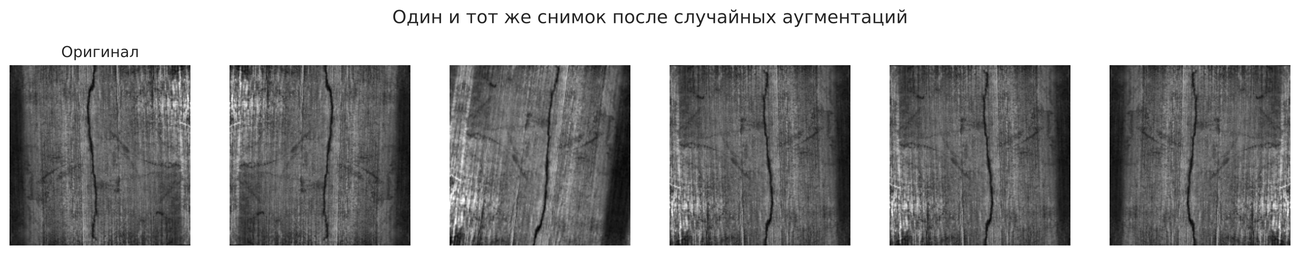

In [23]:
train_aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), scale=(0.9, 1.1), border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
])

class TileDataset(Dataset):
    def __init__(self, images, labels, aug=None):
        self.images, self.labels, self.aug = images, labels, aug

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = self.images[i]
        if self.aug is not None:
            img = self.aug(image=img)["image"]
        return to_tensor(img[None])[0], int(self.labels[i])     # (3, H, W)

idx_train, idx_test = group_folds[0]
assert not set(groups[idx_train]) & set(groups[idx_test])   # ни один участок не попал в обе части

ds_train = TileDataset(X_net[idx_train], y_all[idx_train], aug=train_aug)
ds_test = TileDataset(X_net[idx_test], y_all[idx_test])
dl_train = DataLoader(ds_train, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED))
dl_test = DataLoader(ds_test, batch_size=64)

split_table = pd.DataFrame({"train": np.bincount(y_all[idx_train], minlength=6),
                            "test": np.bincount(y_all[idx_test], minlength=6)}, index=CLASSES)
split_table.loc["Всего"] = split_table.sum()
display(split_table.T)

# Проверяем глазами, что аугментации не уничтожают дефект
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
sample_i = int(idx_train[y_all[idx_train] == CLASS_TO_IDX["Crack"]][0])
axes[0].imshow(X_net[sample_i], cmap="gray"); axes[0].set_title("Оригинал"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(train_aug(image=X_net[sample_i])["image"], cmap="gray"); ax.axis("off")
plt.suptitle("Один и тот же снимок после случайных аугментаций", y=1.02); plt.tight_layout(); plt.show()

In [24]:
@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    return torch.cat([model(x.to(DEVICE)).softmax(dim=1).cpu() for x, _ in loader]).numpy()

set_seed()
model = load_resnet18()
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))    # новая "голова" на 6 классов
model = model.to(DEVICE)

EPOCHS = 8
counts = np.bincount(y_all[idx_train], minlength=len(CLASSES))
class_weights = torch.tensor(len(idx_train) / (len(CLASSES) * counts), dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

backbone_params = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
optimizer = torch.optim.AdamW([{"params": backbone_params, "lr": 5e-4},
                               {"params": model.fc.parameters(), "lr": 5e-3}], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = []
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for x, y in dl_train:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)
    scheduler.step()

    # Метрика на тесте записывается только для построения графика; решений по ней не принимается.
    p = predict_proba(model, dl_test)
    history.append({"epoch": epoch, "train_loss": running / len(ds_train),
                    "test_f1": f1_score(y_all[idx_test], p.argmax(1), average="macro")})
    print(f"Эпоха {epoch} | train loss {history[-1]['train_loss']:.3f} | test macro-F1 {history[-1]['test_f1']:.3f} "
          f"| {time.time() - t0:.0f} с")

history = pd.DataFrame(history)
proba_ft = predict_proba(model, dl_test)

Эпоха 1 | train loss 1.778 | test macro-F1 0.108 | 72 с


Эпоха 2 | train loss 1.445 | test macro-F1 0.323 | 141 с


Эпоха 3 | train loss 1.103 | test macro-F1 0.235 | 206 с


Эпоха 4 | train loss 0.835 | test macro-F1 0.283 | 270 с


Эпоха 5 | train loss 0.556 | test macro-F1 0.350 | 337 с


Эпоха 6 | train loss 0.434 | test macro-F1 0.424 | 407 с


Эпоха 7 | train loss 0.377 | test macro-F1 0.471 | 473 с


Эпоха 8 | train loss 0.343 | test macro-F1 0.453 | 546 с


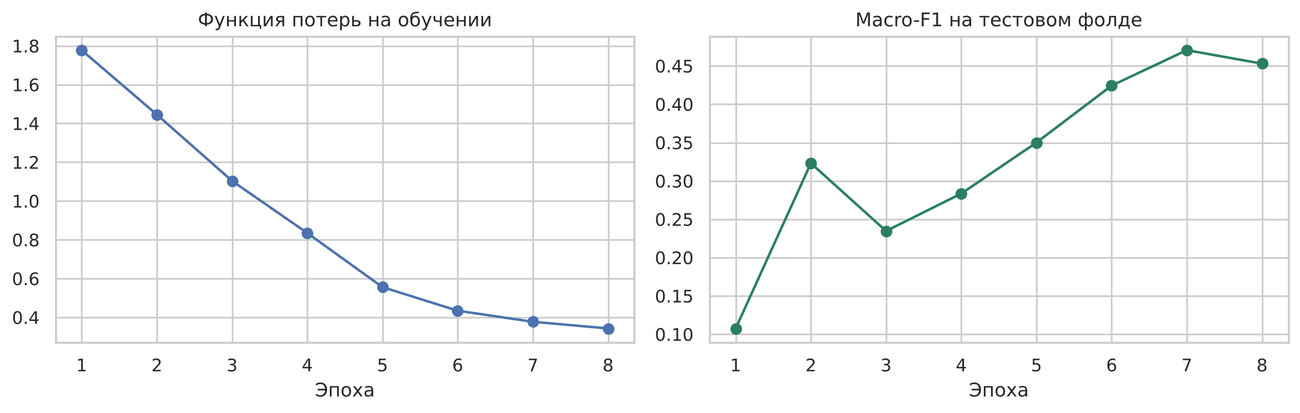

Сравнение на одном и том же тестовом фолде


,Balanced accuracy,Macro-F1,ROC-AUC (дефект / годная)
HOG + LBP + SVM,0.262,0.277,0.708
ResNet-18 (признаки) + LogReg,0.371,0.365,0.772
"ResNet-18, дообучение",0.489,0.453,0.791


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(history["epoch"], history["train_loss"], marker="o")
axes[0].set(title="Функция потерь на обучении", xlabel="Эпоха")
axes[1].plot(history["epoch"], history["test_f1"], marker="o", color="#2a7f62")
axes[1].set(title="Macro-F1 на тестовом фолде", xlabel="Эпоха")
plt.tight_layout(); plt.show()

def fold_metrics(y_pred, defect_score):
    yt = y_all[idx_test]
    return {"Balanced accuracy": balanced_accuracy_score(yt, y_pred),
            "Macro-F1": f1_score(yt, y_pred, average="macro"),
            "ROC-AUC (дефект / годная)": roc_auc_score(yt != FREE, defect_score)}

fold_table = pd.DataFrame({
    "HOG + LBP + SVM": fold_metrics(pred_svm[idx_test], -svm_decision[idx_test, FREE]),
    "ResNet-18 (признаки) + LogReg": fold_metrics(proba_deep[idx_test].argmax(1), 1 - proba_deep[idx_test, FREE]),
    "ResNet-18, дообучение": fold_metrics(proba_ft.argmax(1), 1 - proba_ft[:, FREE]),
}).T.round(3)
print("Сравнение на одном и том же тестовом фолде")
fold_table

**Вывод по разделу.** На этом фолде дообученная сеть показала лучший macro-F1 (0.453 против 0.365 у замороженных признаков и 0.277 у SVM). В бинарной постановке разница между двумя нейросетевыми вариантами невелика: ROC-AUC 0.791 и 0.772.

Делать из этого вывод о преимуществе дообучения было бы преждевременно, и вот почему.

- Оценка получена на одном фолде и при одном значении зерна генератора. Кривая macro-F1 по эпохам немонотонна (0.323 на второй эпохе, 0.235 на третьей), то есть разброс от эпохи к эпохе сопоставим с разницей между моделями.
- В тестовом фолде у редких классов всего два-три участка, поэтому снимки одного участка решают исход.
- Функция потерь на обучении упала с 1.78 до 0.34, а качество на тесте осталось умеренным. Сеть хорошо подстраивается под обучающие участки, но это знание переносится на новые лишь частично.

Дообучение стоит около девяти минут счёта на процессоре против полминуты для замороженных признаков. Надёжно сравнить два подхода можно только полной кросс-валидацией с несколькими запусками, для чего нужен графический ускоритель.

## 10. Итоговое сравнение

Итоговая таблица построена по объединённым предсказаниям пяти фолдов (раздел 7). Дообученная сеть в неё не включена, так как оценивалась на одном фолде.

In [26]:
def cluster_bootstrap_ci(y_pred, n_boot=1000, seed=SEED):
    # С возвращением выбираются группы целиком: снимки одного участка зависимы.
    rng = np.random.default_rng(seed)
    members = [np.where(groups == g)[0] for g in np.unique(groups)]
    scores = []
    for _ in range(n_boot):
        s = np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
        scores.append(f1_score(y_all[s], y_pred[s], average="macro"))
    return np.percentile(scores, [2.5, 97.5])

final = pd.DataFrame(results).T
ci = {name: cluster_bootstrap_ci(pred) for name, pred in predictions.items()}
final["95% ДИ для Macro-F1"] = [f"[{ci[n][0]:.3f}; {ci[n][1]:.3f}]" for n in final.index]
final.round(3)

,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC (дефект / годная),95% ДИ для Macro-F1
Константный прогноз,0.708,0.167,0.138,0.500,[0.131; 0.147]
HOG + LBP + SVM,0.713,0.236,0.252,0.728,[0.191; 0.311]
ResNet-18 (признаки) + LogReg,0.747,0.431,0.457,0.825,[0.368; 0.539]


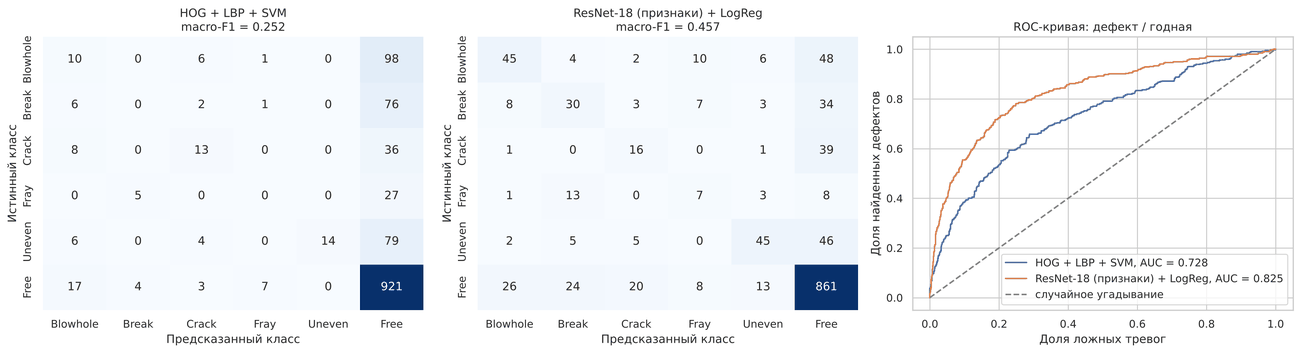

In [27]:
MODELS = ["HOG + LBP + SVM", "ResNet-18 (признаки) + LogReg"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, MODELS):
    cm = confusion_matrix(y_all, predictions[name], labels=range(len(CLASSES)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set(title=f"{name}\nmacro-F1 = {results[name]['Macro-F1']:.3f}", xlabel="Предсказанный класс", ylabel="Истинный класс")
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_all != FREE, defect_scores[name])
    axes[2].plot(fpr, tpr, label=f"{name}, AUC = {results[name]['ROC-AUC (дефект / годная)']:.3f}")
axes[2].plot([0, 1], [0, 1], ls="--", color="gray", label="случайное угадывание")
axes[2].set(title="ROC-кривая: дефект / годная", xlabel="Доля ложных тревог", ylabel="Доля найденных дефектов")
axes[2].legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison.png", dpi=110, bbox_inches="tight"); plt.show()

In [28]:
per_class = pd.DataFrame({name: pd.Series(f1_score(y_all, predictions[name], average=None), index=CLASSES) for name in MODELS})
per_class["Уникальных участков"] = df.groupby("label")["group"].nunique().loc[CLASSES]
print("F1-мера по классам")
per_class.round(3)

F1-мера по классам


,HOG + LBP + SVM,ResNet-18 (признаки) + LogReg,Уникальных участков
Blowhole,0.123,0.455,20
Break,0.000,0.373,15
Crack,0.306,0.311,12
Fray,0.000,0.219,4
Uneven,0.239,0.517,17
Free,0.841,0.866,159


In [29]:
# Практический вопрос: какую долю дефектных снимков модель находит, если разрешить ей
# забраковать зря не более 10 % годных? Порог выбирается по ROC-кривой.
rows = {}
for name in MODELS:
    fpr, tpr, _ = roc_curve(y_all != FREE, defect_scores[name])
    rows[name] = {"Найдено дефектных при 10 % ложных тревог": tpr[fpr <= 0.10].max()}
pd.DataFrame(rows).T.round(3)

,Найдено дефектных при 10 % ложных тревог
HOG + LBP + SVM,0.385
ResNet-18 (признаки) + LogReg,0.554


**Обсуждение результатов.**

1. **Обе модели лучше константного прогноза, но задача далека от решения.** Лучший результат в честной схеме - macro-F1 0.457 с 95 %-м доверительным интервалом [0.368; 0.539]. Интервал широкий, что отражает реальный объём данных: 68 дефектных участков на пять классов.
2. **Перенос обучения даёт основной прирост.** Macro-F1 классической модели равен 0.252 с интервалом [0.191; 0.311]. Интервалы двух моделей не пересекаются.
3. **Accuracy почти не различает модели** (0.708, 0.713, 0.747), хотя по macro-F1 они различаются более чем втрое. Это иллюстрирует, почему при дисбалансе классов accuracy не подходит в качестве основной метрики.
4. **Главная ошибка обеих моделей - пропуск дефекта.** В матрицах ошибок больше всего внедиагональных значений в столбце `Free`. Классическая модель относит к годным подавляющее большинство дефектных снимков и ни разу верно не распознаёт классы `Break` и `Fray`.
5. **Качество по классам связано с числом уникальных участков.** Хуже всего распознаётся `Fray` (F1 0.219, 4 участка) и `Crack` (0.311, 12 участков), лучше всего `Uneven` (0.517) и `Blowhole` (0.455), у которых участков 17 и 20.
6. **В бинарной постановке результат более практичен, но для производства недостаточен.** При допустимых 10 % ложных тревог лучшая модель находит 55 % дефектных снимков, классическая 39 %. Почти половина брака при таком пороге прошла бы контроль.

## 11. Интерпретация: Grad-CAM

Метрика не говорит, на что именно опирается модель. Сеть могла выучить побочный признак, например общую яркость кадра или форму края плитки. Проверить это позволяет метод **Grad-CAM** (Selvaraju et al., 2017).

Пусть $A^k$ - $k$-я карта признаков последнего свёрточного блока, $z_c$ - выход сети для класса $c$. Важность карты оценивается усреднённым по пространству градиентом:

$$\alpha_k^c = \frac{1}{HW}\sum_{i,j} \frac{\partial z_c}{\partial A^k_{ij}}, \qquad L^c = \mathrm{ReLU}\Bigl(\sum_k \alpha_k^c A^k\Bigr).$$

Карта $L^c$ показывает, какие участки изображения сильнее всего повышают уверенность сети в классе $c$. У нас есть размеченные маски дефектов, поэтому тепловую карту можно сопоставить с истинным положением дефекта. Маски в обучении не участвовали: сеть видела только метку класса. Метод применяется к дообученной сети из раздела 9 на снимках её тестового фолда.

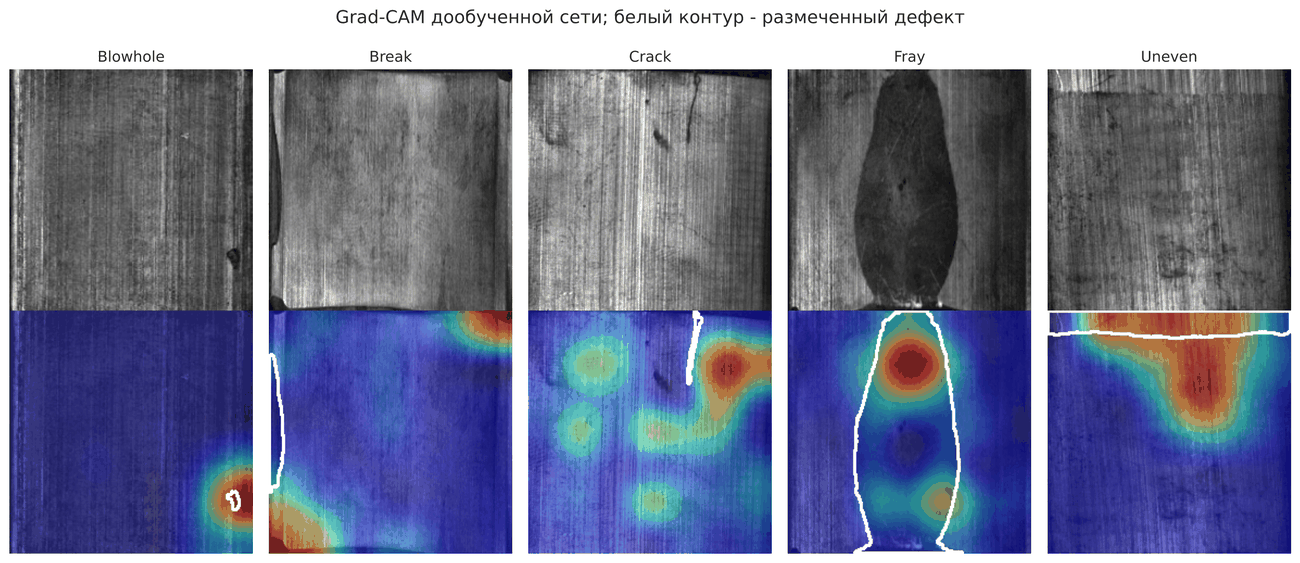

In [30]:
def grad_cam(model, x, target_class):
    # x: тензор (1, 3, H, W). Возвращает карту в диапазоне [0, 1] размером с входное изображение.
    model.eval()
    feats = {}
    hook = model.layer4.register_forward_hook(lambda m, i, o: feats.update(a=o))
    logits = model(x)
    hook.remove()
    grads = torch.autograd.grad(logits[0, target_class], feats["a"])[0]     # dz_c / dA
    weights = grads.mean(dim=(2, 3), keepdim=True)                           # alpha_k
    cam = F.relu((weights * feats["a"]).sum(dim=1))[0].detach().cpu().numpy()
    cam = cv2.resize(cam, (x.shape[-1], x.shape[-2]), interpolation=cv2.INTER_CUBIC)
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

def overlay(img_gray, cam, mask=None):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)                             # OpenCV хранит цвет в порядке BGR
    vis = cv2.addWeighted(cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB), 0.55, heat, 0.45, 0)
    if mask is not None:
        cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, cnts, -1, (255, 255, 255), 2)
    return vis

def load_mask(i):
    m = cv2.imread(df.loc[i, "mask_path"], cv2.IMREAD_GRAYSCALE)
    return (cv2.resize(m, (NET_SIZE, NET_SIZE), interpolation=cv2.INTER_NEAREST) > 0).astype(np.uint8)

pred_ft = proba_ft.argmax(1)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for c, cls in enumerate(CLASSES[:-1]):
    k = CLASS_TO_IDX[cls]
    # по возможности берём верно распознанный снимок; если таких нет, первый снимок класса
    correct = [i for i, p in zip(idx_test, pred_ft) if y_all[i] == k and p == k]
    i = correct[0] if correct else int(idx_test[y_all[idx_test] == k][0])
    cam = grad_cam(model, to_tensor(X_net[i][None]).to(DEVICE), k)
    axes[0, c].imshow(X_net[i], cmap="gray"); axes[0, c].axis("off")
    axes[0, c].set_title(f"{cls}" + ("" if correct else " (ошибка сети)"))
    axes[1, c].imshow(overlay(X_net[i], cam, load_mask(i))); axes[1, c].axis("off")
plt.suptitle("Grad-CAM дообученной сети; белый контур - размеченный дефект", y=1.0)
plt.tight_layout(); plt.savefig(FIG_DIR / "gradcam.png", dpi=110, bbox_inches="tight"); plt.show()

Визуальная оценка субъективна, поэтому добавим количественную проверку, известную как *pointing game*. Для каждого дефектного снимка тестового фолда проверяется, попадает ли максимум тепловой карты истинного класса внутрь размеченной маски. Допуск составляет 16 пикселей: карта получена растяжением сетки $7 \times 7$, одна её ячейка соответствует 32 пикселям, и точнее локализовать она не может. Для сравнения приводится доля кадра, которую занимает маска с тем же допуском. Такой была бы вероятность попадания случайной точки.

In [31]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (33, 33))   # дилатация на 16 пикселей во все стороны
rows = []
for i in idx_test:
    if y_all[i] == FREE:
        continue
    cam = grad_cam(model, to_tensor(X_net[i][None]).to(DEVICE), int(y_all[i]))
    mask = cv2.dilate(load_mask(i), kernel)
    r, c = np.unravel_index(cam.argmax(), cam.shape)
    rows.append({"label": CLASSES[y_all[i]], "hit": bool(mask[r, c]), "chance": mask.mean()})

pg_raw = pd.DataFrame(rows)
pg = pg_raw.groupby("label").agg(n=("hit", "size"), hit=("hit", "mean"), chance=("chance", "mean")).reindex(CLASSES[:-1])
pg.loc["Все дефекты"] = [len(pg_raw), pg_raw["hit"].mean(), pg_raw["chance"].mean()]
pg.columns = ["Снимков", "Доля попаданий максимума в маску", "Вероятность случайного попадания"]
pg.round(3)

,Снимков,Доля попаданий максимума в маску,Вероятность случайного попадания
label,,,
Blowhole,24.0,0.875,0.030
Break,17.0,0.647,0.072
Crack,11.0,0.182,0.065
Fray,14.0,0.429,0.312
Uneven,18.0,0.667,0.238
Все дефекты,84.0,0.619,0.134


**Вывод по разделу.** В среднем максимум тепловой карты попадает в область дефекта в 62 % случаев при 13 % для случайной точки. Сеть обучалась только на метках класса и разметку масок не видела, так что она действительно научилась находить часть дефектов, а не опирается целиком на побочные признаки.

По классам картина неоднородна.

- **`Blowhole`**: 88 % попаданий при 3 % случайных. Это самый убедительный результат: раковина занимает доли процента кадра, и сеть находит именно её.
- **`Break` и `Uneven`**: около 65 % попаданий, заметно выше случайного уровня.
- **`Fray`**: 43 % при 31 % случайных. Разница невелика, и при столь малом числе участков ничего определённого утверждать нельзя.
- **`Crack`**: 18 % при 7 % случайных. Трещину сеть в основном не локализует, что согласуется с низким качеством классификации этого класса. Тонкая линия шириной в несколько пикселей плохо сохраняется на карте признаков размером $7 \times 7$.

В подсчёт включены все дефектные снимки тестового фолда, в том числе классифицированные неверно.

## 12. Выводы

**Что сделано.** На открытом наборе снимков магнитной плитки построен полный цикл решения задачи классификации дефектов: разведочный анализ, предобработка в OpenCV, сегментация по правилам, классическая модель на признаках HOG и LBP, перенос обучения с ResNet-18, дообучение сети на PyTorch, интерпретация с помощью Grad-CAM.

**Основные результаты.**

1. **В наборе данных обнаружена утечка.** Каждый участок плитки снят примерно шесть раз при разной экспозиции. При случайном разбиении копии попадают и в обучение, и в тест. Одна и та же модель показывает macro-F1 0.954 при случайном разбиении и 0.252 при разбиении по участкам.
2. **Реальный объём данных на порядок меньше номинального:** около 230 уникальных участков вместо 1344 снимков, из них 68 дефектных.
3. **В честной схеме лучший результат даёт перенос обучения:** macro-F1 0.457 (95 % ДИ [0.368; 0.539]) и ROC-AUC 0.825 в постановке «дефект / годная» против 0.252 и 0.728 у классической модели.
4. **Сегментация по правилам неприменима:** средний IoU не выше 0.14, а на годных плитках алгоритм срабатывает в 97 % случаев.
5. **Дообученная сеть частично локализует дефекты без разметки масок:** максимум Grad-CAM попадает в дефект в 62 % случаев при 13 % для случайной точки.
6. **Для производственного применения качество недостаточно:** при 10 % ложных тревог обнаруживается около 55 % дефектных снимков.

**Ограничения работы.**

- Группы снимков восстановлены эвристически, по сходству дескрипторов. Идентификаторов участков в данных нет, поэтому отдельные ошибки группировки возможны.
- Не проверялось, встречаются ли кадры одной физической плитки в разных классах (например, дефектный и годный участки одной плитки).
- Дообучение сети оценено на одном фолде и одном запуске. Вариант признаков ResNet-18 выбран по той же кросс-валидации, на которой оценён.
- Снимки приводятся к квадрату с искажением пропорций, а мелкие дефекты при уменьшении частично теряются.
- Гиперпараметры моделей подбирались минимально.

**Возможные направления развития.**

- **Использовать маски дефектов при обучении.** Сейчас сеть получает одну метку на снимок. Обучение сегментационной модели (например, U-Net) даёт метку на каждый пиксель, то есть значительно больше информации с того же числа участков.
- **Постановка как поиск аномалий.** Годных участков 159, дефектных мало. Естественно обучать модель только на годных и искать отклонения от нормы (методы семейства PaDiM и PatchCore), тогда редкость дефектов перестаёт быть препятствием.
- **Работа в исходном разрешении по фрагментам**, чтобы не терять раковины и трещины при уменьшении.
- **Полная кросс-валидация дообучения с несколькими запусками** на графическом ускорителе.

Основной урок работы относится не к конкретной модели, а к методике: прежде чем сравнивать модели, нужно убедиться, что схема оценки измеряет именно обобщающую способность.